# 03 · EDA de los episodios de urgencias

**Objetivo.** Describir los episodios de urgencias de la población de análisis (D9): tamaño de los tres grupos (D6), tiempo de permanencia (LOS, D5), perfil de los episodios, contactos breves y reconsultas (D7). Cierra con un resumen en el marco de Asplin (entrada → procesos → salida).

**Qué lee.** Solo `data/interim/episodios_urgencias_60min.parquet`, generado por el notebook 02. No consulta la base. Trabaja con `en_poblacion == True` (llegada entre 2023-01-01 y 2026-03-31); los episodios posteriores solo cuentan como "siguiente episodio" en las reconsultas.

**Qué produce.**
- Tablas agregadas con supresión de celdas pequeñas y figuras `reports/figures/03_*.png|svg`.
- Para el dashboard (agregadas y con supresión): `data/processed/resumen_los.csv`, `data/processed/resumen_reconsultas.csv` y `data/processed/resumen_grupos_mes.csv`.

Umbral operativo del hospital: **12 horas** en urgencias.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter

from src import config, estilo
from src.estadistica import ecdf_en_malla, tabla_los, tabla_proporciones
from src.estilo import fmt_entero, fmt_horas, fmt_pct
from src.graficos import (
    COLORES_GRUPO,
    DIAS_SEMANA,
    ETIQUETAS_CORTAS_GRUPO,
    TEXTO_PRIMARIO,
    TEXTO_SECUNDARIO,
    activar_formato_tablas,
    ancho_linea,
    aplicar_estilo,
    etiquetas_directas,
    guardar_figura,
    heatmap_hora_dia,
    leyenda_fuera,
    linea_umbral,
    marcar_umbrales,
    rotular_barras,
    titulo_hallazgo,
)
from src.privacidad import enmascarar_pequenos, suprimir_pequenos, tabla_segura

aplicar_estilo()
activar_formato_tablas()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

G1, G2, G3 = config.GRUPOS
UMBRAL = config.UMBRAL_OPERATIVO_H
SUFIJO = f'mas_{UMBRAL}h'
ERROR_KW = {'elinewidth': 1, 'ecolor': TEXTO_SECUNDARIO}
ORDEN_EDAD = list(config.GRUPOS_ETARIOS) + ['sin_dato']
OSCURO, MEDIO, CLARO = estilo.GRISES


def puntos_validos(tabla, eventos='n_eventos'):
    """Para gráficos: solo se dibujan proporciones con denominador y numerador de al menos MIN_CELDA."""
    return (tabla['n'] >= config.MIN_CELDA) & (tabla[eventos] >= config.MIN_CELDA)


def barras_con_ic(ax, x, tabla, columna_pct, columna_inf, columna_sup, valido, ancho, desplazamiento, **estilo_barras):
    """Barras de porcentaje con IC de Wilson; las celdas no válidas quedan vacías."""
    pct = tabla[columna_pct].where(valido)
    errores = np.vstack([(pct - tabla[columna_inf]).to_numpy(), (tabla[columna_sup] - pct).to_numpy()])
    barras = ax.bar(x + desplazamiento, pct, width=ancho, yerr=errores, capsize=4, error_kw=ERROR_KW, **estilo_barras)
    rotular_barras(ax, barras, pct, formato=fmt_pct, alturas=tabla[columna_sup].where(valido))
    return barras


def valor_seguro(tabla, fila, columna, conteo='n'):
    """Valor de una tabla agregada para un título, o NaN si su conteo es menor a MIN_CELDA."""
    if fila not in tabla.index or tabla.loc[fila, conteo] < config.MIN_CELDA:
        return np.nan
    return tabla.loc[fila, columna]

In [2]:
ruta_episodios = config.DATA_INTERIM / f'episodios_urgencias_{config.UMBRAL_FUSION_MIN}min.parquet'
if not ruta_episodios.exists():
    raise FileNotFoundError('No existe el parquet de episodios: ejecuta primero notebooks/02_del_dato_al_episodio.ipynb.')

episodios = pd.read_parquet(ruta_episodios)
episodios['hora_llegada'] = episodios['llegada'].dt.hour
episodios['dia_semana'] = episodios['llegada'].dt.dayofweek
episodios['mes'] = episodios['llegada'].dt.to_period('M').dt.to_timestamp()
los_con_tiempo = episodios['los_h'].where(episodios['grupo'].isin(list(config.GRUPOS_TIEMPOS)))
episodios['tramo_los'] = pd.cut(
    los_con_tiempo, bins=[0, 4, 12, 24, np.inf], right=False,
    labels=['menos de 4 h', '4 a 12 h', '12 a 24 h', '24 h o más'],
)

poblacion = episodios[episodios['en_poblacion']].copy()
tiempos = poblacion[poblacion['grupo'].isin(list(config.GRUPOS_TIEMPOS))]
print('Episodios construidos (filas, columnas):', episodios.shape)
print('Episodios en la población (D9):', len(poblacion))
print('Episodios con tiempos (grupos 2 y 3):', len(tiempos))

Episodios construidos (filas, columnas): (471215, 40)
Episodios en la población (D9): 445237
Episodios con tiempos (grupos 2 y 3): 227898


# Parte A · Univariado
## 1. Tamaño de los tres grupos

,n_episodios,pct_episodios
grupo,,
1_contacto_breve,217.339,"48,8"
2_atencion_urgencias,193.241,"43,4"
3_hospitalizado,34.657,"7,8"


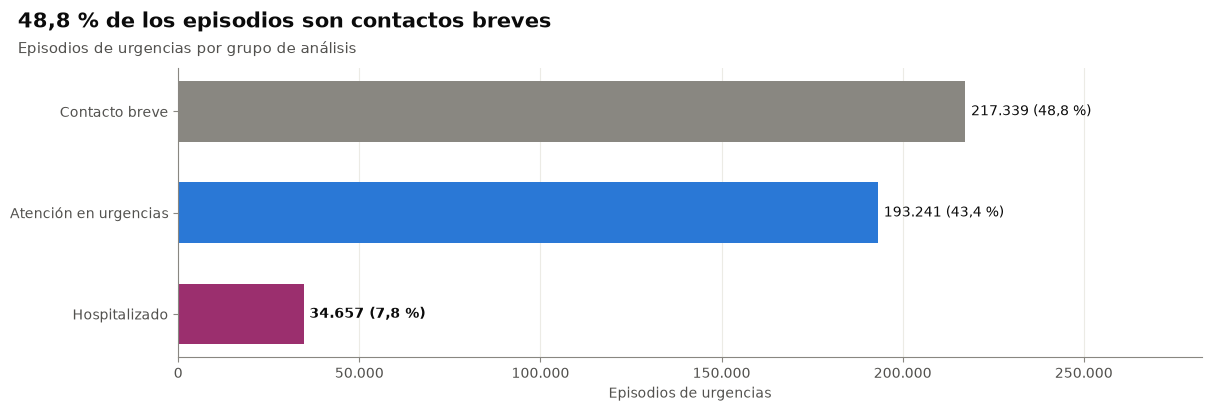

In [3]:
tamano = (
    poblacion['grupo'].value_counts()
    .reindex(list(config.GRUPOS), fill_value=0)
    .rename_axis('grupo')
    .rename('n_episodios')
    .to_frame()
)
tamano['pct_episodios'] = 100 * tamano['n_episodios'] / tamano['n_episodios'].sum()
display(tabla_segura(tamano, decimales=1))

fig, ax = plt.subplots(figsize=(12, 4))
y = np.arange(len(tamano))[::-1]
ax.barh(y, tamano['n_episodios'], height=0.6, color=[COLORES_GRUPO[g] for g in tamano.index])
for yi, grupo, n, pct in zip(y, tamano.index, tamano['n_episodios'], tamano['pct_episodios']):
    texto = f'<{config.MIN_CELDA}' if n < config.MIN_CELDA else f'{fmt_entero(n)} ({fmt_pct(pct)})'
    ax.annotate(texto, xy=(n, yi), xytext=(4, 0), textcoords='offset points', va='center', color=TEXTO_PRIMARIO,
                fontweight='bold' if grupo == G3 else 'normal')
ax.set_yticks(y, [ETIQUETAS_CORTAS_GRUPO[g] for g in tamano.index])
ax.set_xlim(0, tamano['n_episodios'].max() * 1.3)
ax.grid(False)
ax.grid(axis='x')
ax.set_xlabel('Episodios de urgencias')
titulo_hallazgo(fig, f"{fmt_pct(tamano.loc[G1, 'pct_episodios'])} de los episodios son contactos breves",
                'Episodios de urgencias por grupo de análisis')
guardar_figura(fig, '03_tamano_grupos')
plt.show()

### Lectura
Ver el peso del grupo 1 (contactos breves y visitas sin etapas) frente a los grupos con tiempos. Si el grupo 1 es muy grande, los indicadores de LOS de todo urgencias dependerían mucho de cómo se traten estos contactos; por eso se reportan aparte (D6).

## 2. Distribución del LOS (grupos 2 y 3)

ECDF en escala logarítmica, con líneas en 4, 12 y 24 h. La curva se evalúa en una malla fija, sin exponer observaciones individuales.

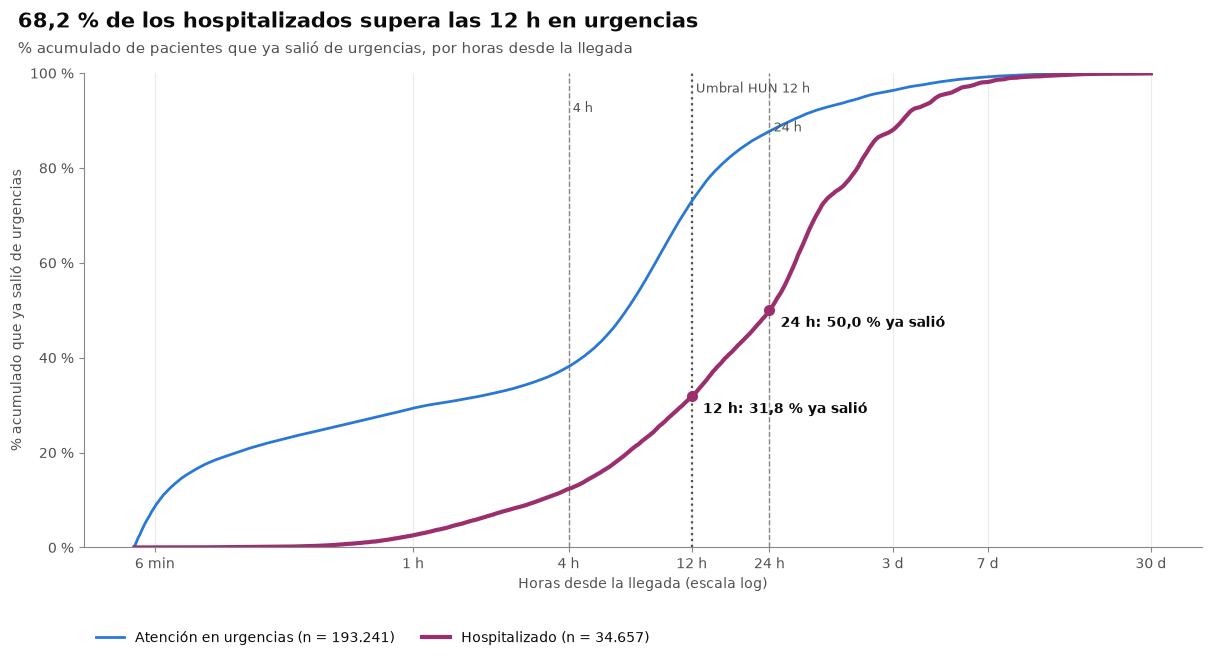

In [4]:
malla = np.logspace(np.log10(5 / 60), np.log10(24 * 30), 600)

fig, ax = plt.subplots(figsize=(12, 6.5))
for grupo in config.GRUPOS_TIEMPOS:
    los = tiempos.loc[tiempos['grupo'] == grupo, 'los_h']
    etiqueta = f'{ETIQUETAS_CORTAS_GRUPO[grupo]} (n = {fmt_entero(los.notna().sum())})'
    ax.plot(malla, ecdf_en_malla(los, malla), color=COLORES_GRUPO[grupo], linewidth=ancho_linea(grupo), label=etiqueta)

# Puntos anotados en 12 h y 24 h para el grupo 3 (proporción que ya salió de urgencias).
los_g3 = tiempos.loc[tiempos['grupo'] == G3, 'los_h'].dropna()
for horas in [12, 24]:
    salio = 100 * (los_g3 <= horas).mean()
    ax.plot(horas, salio / 100, 'o', color=COLORES_GRUPO[G3], markersize=7, zorder=4)
    ax.annotate(f'{fmt_horas(horas, 0)}: {fmt_pct(salio)} ya salió', xy=(horas, salio / 100), xytext=(8, -12),
                textcoords='offset points', color=TEXTO_PRIMARIO, fontweight='bold')
ax.set_xscale('log')
linea_umbral(ax, UMBRAL)
linea_umbral(ax, 4, "4 h", destacada=False, fila=1)
linea_umbral(ax, 24, "24 h", destacada=False, fila=2)
ax.set_xticks([0.1, 1, 4, 12, 24, 72, 168, 720], ['6 min', '1 h', '4 h', '12 h', '24 h', '3 d', '7 d', '30 d'])
ax.minorticks_off()
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _pos: fmt_pct(100 * v, 0)))
ax.grid(axis='both')
ax.set_xlabel('Horas desde la llegada (escala log)')
ax.set_ylabel('% acumulado que ya salió de urgencias')
leyenda_fuera(ax, 'debajo', ncol=2)
titulo_hallazgo(fig, f'{fmt_pct(100 * (los_g3 > UMBRAL).mean())} de los hospitalizados supera las 12 h en urgencias',
                '% acumulado de pacientes que ya salió de urgencias, por horas desde la llegada')
guardar_figura(fig, '03_ecdf_los')
plt.show()

### Lectura
Leer en cada curva la proporción acumulada en 4, 12 y 24 h: 1 menos ese valor es el % de episodios que supera el umbral. Comparar con la referencia de DBeaver (reglas anteriores): mediana de 24,0 h en hospitalizados con hora de piso y de 7,0 h en no hospitalizados con atención. Un escalón al inicio de la curva del grupo 3 corresponde a los LOS recortados a 0 (D3).

## 3. Perfil de los episodios: edad, sexo, hora, día y mes de llegada

grupo,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado
grupo_etario,,,
adulto,135.755,119.107,20.165
adulto_mayor,17.329,24.794,6.907
pediatria,64.242,49.334,7.585
sin_dato,13,<10,<10


grupo,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado
sexo,,,
femenino,117.223,111.810,19.706
masculino,100.099,81.424,14.951
otro_o_sin_dato,17,<10,<10


grupo,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado
hora_llegada,,,
0,3.230,3.090,616
1,2.530,2.148,542
2,1.965,1.866,481
3,1.883,1.670,441
4,1.763,1.682,444
5,3.321,2.616,683
6,7.261,5.275,1.215
7,13.112,9.991,1.937
8,16.803,12.545,2.320


grupo,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado
dia_semana,,,
0,36.591,31.514,5.279
1,36.341,29.967,5.325
2,34.503,28.893,5.112
3,32.668,28.794,5.230
4,31.721,28.100,5.284
5,24.339,23.960,4.332
6,21.176,22.013,4.095


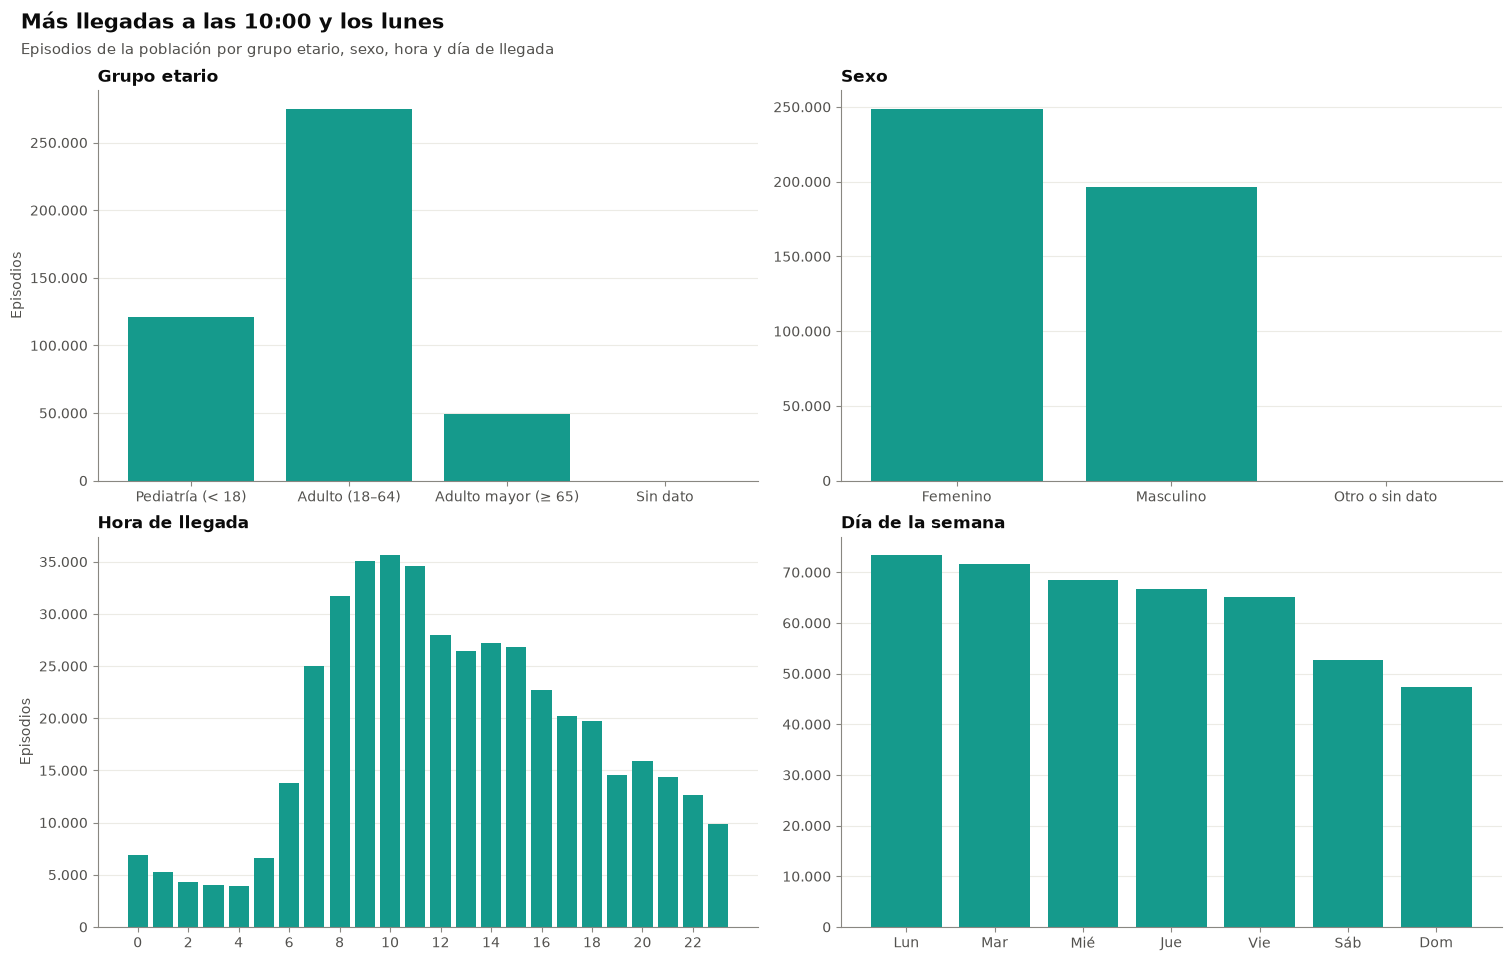

In [5]:
perfil_partes = []
for variable in ['grupo_etario', 'sexo', 'hora_llegada', 'dia_semana']:
    conteo = poblacion.groupby([variable, 'grupo']).size().unstack('grupo', fill_value=0).reindex(
        columns=list(config.GRUPOS), fill_value=0)
    display(suprimir_pequenos(conteo.add_prefix('n_'), list(conteo.add_prefix('n_').columns)))
    perfil_partes.append(conteo)

fig, ejes = plt.subplots(2, 2, figsize=(15, 9.5))
conteo_edad = perfil_partes[0].reindex([e for e in ORDEN_EDAD if e in perfil_partes[0].index]).sum(axis=1)
ejes[0, 0].bar([estilo.NOMBRE_GRUPO_ETARIO[e] for e in conteo_edad.index], enmascarar_pequenos(conteo_edad, conteo_edad), color=estilo.VERDE)
ejes[0, 0].set_title('Grupo etario')
conteo_sexo = perfil_partes[1].sum(axis=1)
ejes[0, 1].bar([estilo.NOMBRE_SEXO.get(s, s) for s in conteo_sexo.index], enmascarar_pequenos(conteo_sexo, conteo_sexo), color=estilo.VERDE)
ejes[0, 1].set_title('Sexo')
conteo_hora = perfil_partes[2].sum(axis=1)
ejes[1, 0].bar(conteo_hora.index, enmascarar_pequenos(conteo_hora, conteo_hora), color=estilo.VERDE)
ejes[1, 0].set_xticks(range(0, 24, 2))
ejes[1, 0].set_title('Hora de llegada')
conteo_dia = perfil_partes[3].sum(axis=1)
ejes[1, 1].bar(conteo_dia.index, enmascarar_pequenos(conteo_dia, conteo_dia), color=estilo.VERDE)
ejes[1, 1].set_xticks(range(7), DIAS_SEMANA)
ejes[1, 1].set_title('Día de la semana')
for ax in ejes[:, 0]:
    ax.set_ylabel('Episodios')
titulo_hallazgo(fig, f'Más llegadas a las {conteo_hora.idxmax():02d}:00 y los {estilo.DIAS_SEMANA_COMPLETOS[conteo_dia.idxmax()]}',
                'Episodios de la población por grupo etario, sexo, hora y día de llegada')
guardar_figura(fig, '03_perfil_episodios')
plt.show()

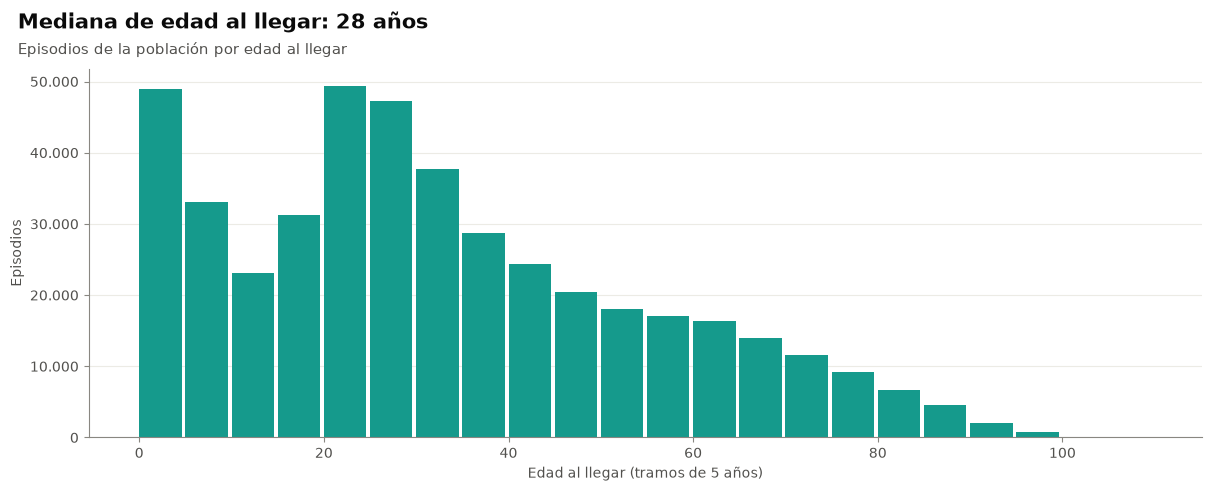

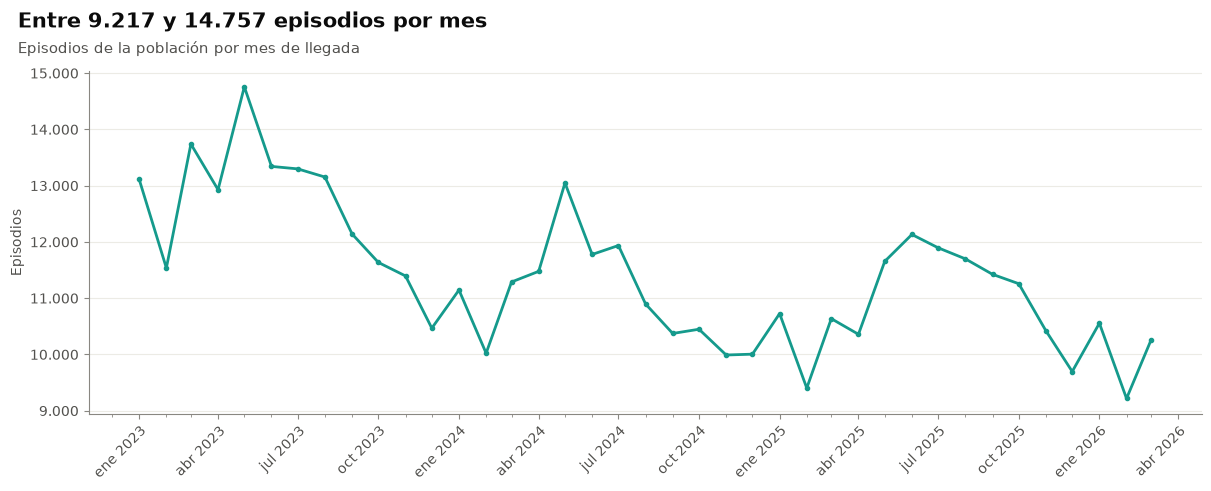

In [6]:
edad_bandas = (poblacion['edad'] // 5 * 5).dropna().astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(edad_bandas.index, enmascarar_pequenos(edad_bandas, edad_bandas), width=4.6, align='edge', color=estilo.VERDE)
ax.set_xlabel('Edad al llegar (tramos de 5 años)')
ax.set_ylabel('Episodios')
titulo_hallazgo(fig, f"Mediana de edad al llegar: {fmt_entero(poblacion['edad'].median())} años",
                'Episodios de la población por edad al llegar')
guardar_figura(fig, '03_edad_episodios')
plt.show()

episodios_mes = poblacion.groupby('mes').size()
fig, ax = plt.subplots(figsize=(12, 4.8))
valores = enmascarar_pequenos(episodios_mes, episodios_mes)
ax.plot(valores.index, valores, marker='o', markersize=3, color=estilo.VERDE)
ax.set_ylabel('Episodios')
titulo_hallazgo(fig, f'Entre {fmt_entero(episodios_mes.min())} y {fmt_entero(episodios_mes.max())} episodios por mes',
                'Episodios de la población por mes de llegada')
guardar_figura(fig, '03_episodios_mes')
plt.show()

### Lectura
Ubicar los picos de llegada por hora y día (entrada del modelo de Asplin) y la composición por edad y sexo. En la serie mensual, buscar estacionalidad (por ejemplo, temporadas respiratorias) y descartar quiebres de registro dentro del periodo de análisis.

## 4. Variables nuevas por grupo: `hosp_previa_30d` y `nota_consulta_urg` (D11)

n  n_eventos  pct_eventos  ic_inf_eventos  ic_sup_eventos
variable          grupo                                                                               
hosp_previa_30d   1_contacto_breve      217339       2952         1.36            1.31            1.41
                  2_atencion_urgencias  193241       3049         1.58            1.52            1.63
                  3_hospitalizado        34657        663         1.91            1.77            2.06
nota_consulta_urg 1_contacto_breve      217339      71974        33.12           32.92           33.31
                  2_atencion_urgencias  193241     109816        56.83           56.61           57.05
                  3_hospitalizado        34657      22256        64.22           63.71           64.72

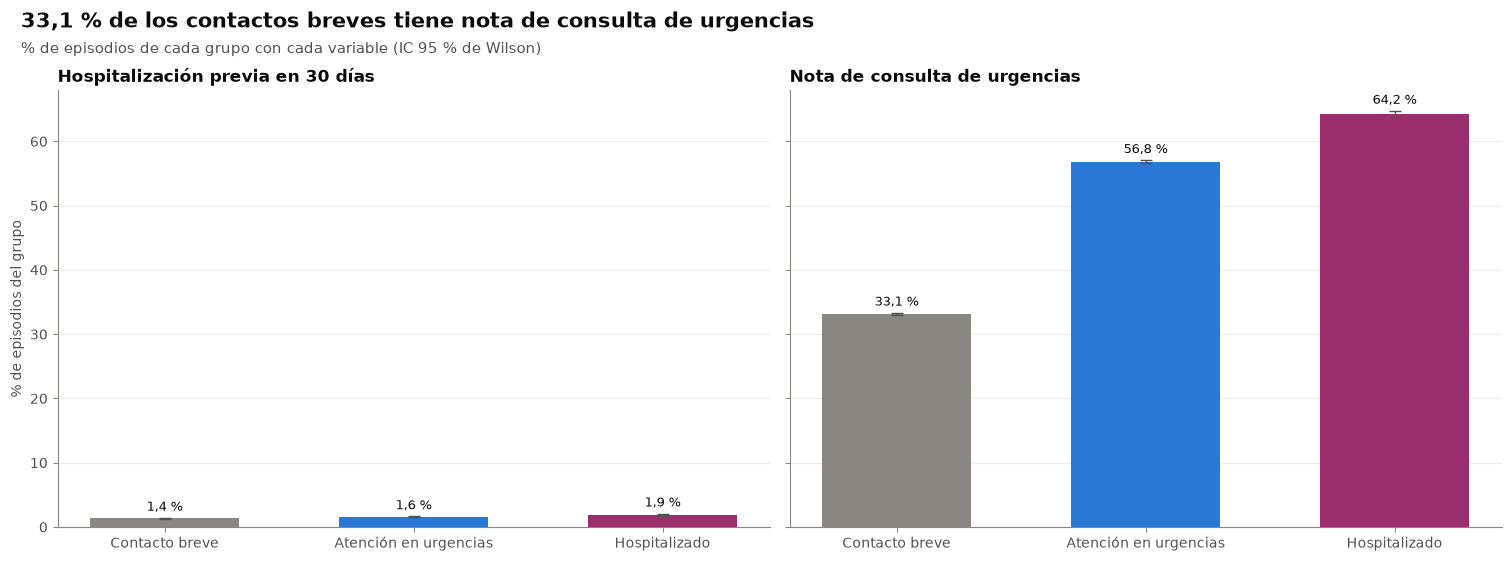

In [7]:
nuevas = []
for variable in ['hosp_previa_30d', 'nota_consulta_urg']:
    tabla = tabla_proporciones(poblacion, ['grupo'], variable)
    nuevas.append(tabla.assign(variable=variable).set_index('variable', append=True))
nuevas = pd.concat(nuevas).reorder_levels(['variable', 'grupo'])
display(tabla_segura(nuevas))

grupos = list(config.GRUPOS)
x = np.arange(len(grupos))
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, (variable, titulo) in zip(ejes, [('hosp_previa_30d', 'Hospitalización previa en 30 días'),
                                          ('nota_consulta_urg', 'Nota de consulta de urgencias')]):
    tabla = nuevas.xs(variable, level='variable').reindex(grupos)
    barras_con_ic(ax, x, tabla, 'pct_eventos', 'ic_inf_eventos', 'ic_sup_eventos', puntos_validos(tabla), 0.6, 0,
                  color=[COLORES_GRUPO[g] for g in grupos])
    ax.set_xticks(x, [ETIQUETAS_CORTAS_GRUPO[g] for g in grupos])
    ax.set_title(titulo)
ejes[0].set_ylabel('% de episodios del grupo')
nota_g1 = valor_seguro(nuevas.xs('nota_consulta_urg', level='variable'), G1, 'pct_eventos', 'n_eventos')
titulo_hallazgo(fig, f'{fmt_pct(nota_g1)} de los contactos breves tiene nota de consulta de urgencias',
                '% de episodios de cada grupo con cada variable (IC 95 % de Wilson)')
guardar_figura(fig, '03_variables_nuevas')
plt.show()

### Lectura
- `nota_consulta_urg` debería ser baja en el grupo 1 y alta en los grupos 2 y 3: si un contacto breve tiene nota de consulta, hubo atención médica registrada aunque dure menos de 5 min.
- `hosp_previa_30d` mide reingresos: ver si es más frecuente en el grupo 3.

# Parte B · Bivariado
## 5. LOS por grupo

n, mediana, p25, p75 y p90 en horas, y % por encima de 4, 6, 8, 12, 24 y 72 h con IC de Wilson al 95 %.

In [8]:
resumen_grupos = tabla_los(tiempos, ['grupo'])
tabla_segura(resumen_grupos)

,n,mediana_h,p25_h,p75_h,p90_h,n_mas_4h,pct_mas_4h,ic_inf_mas_4h,ic_sup_mas_4h,n_mas_6h,pct_mas_6h,ic_inf_mas_6h,ic_sup_mas_6h,n_mas_8h,pct_mas_8h,ic_inf_mas_8h,ic_sup_mas_8h,n_mas_12h,pct_mas_12h,ic_inf_mas_12h,ic_sup_mas_12h,n_mas_24h,pct_mas_24h,ic_inf_mas_24h,ic_sup_mas_24h,n_mas_72h,pct_mas_72h,ic_inf_mas_72h,ic_sup_mas_72h
grupo,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2_atencion_urgencias,193.241,"6,69","0,46","12,74","29,17",119.547,"61,9","61,6","62,1",103.442,"53,5","53,3","53,8",83.770,"43,4","43,1","43,6",52.231,"27,0","26,8","27,2",23.675,"12,2","12,1","12,4",7.081,"3,7","3,6","3,8"
3_hospitalizado,34.657,"23,98","8,77","43,18","78,55",30.380,"87,7","87,3","88,0",28.514,"82,3","81,9","82,7",26.641,"76,9","76,4","77,3",23.621,"68,2","67,7","68,6",17.320,"50,0","49,5","50,5",4.158,"12,0","11,7","12,3"


### Lectura
Leer la fila del grupo 3 en `pct_mas_12h` (referencia de DBeaver con reglas anteriores: 68,2 % > 12 h y 50,0 % > 24 h) y la del grupo 2 (referencia: 28,0 % > 12 h). La amplitud de los IC indica si las diferencias entre grupos son claras.

## 6. LOS y % > 12 h por grupo etario y sexo

In [9]:
columnas = ['n', 'mediana_h', 'p25_h', 'p75_h', 'p90_h', f'n_{SUFIJO}', f'pct_{SUFIJO}', f'ic_inf_{SUFIJO}', f'ic_sup_{SUFIJO}']
for variable in ['grupo_etario', 'sexo']:
    display(tabla_segura(tabla_los(tiempos, ['grupo', variable])[columnas]))

n  mediana_h      p25_h      p75_h      p90_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h
grupo                grupo_etario                                                                                                        
2_atencion_urgencias adulto        119107       7.28       1.16      13.04      29.21     33454       28.09          27.83          28.34
                     adulto_mayor   24794       9.35       4.27      17.85      55.07      9400       37.91          37.31          38.52
                     pediatria      49334       1.69       0.13       9.47      20.77      9375        19.0          18.66          19.35
                     sin_dato         <10  suprimido  suprimido  suprimido  suprimido       <10   suprimido      suprimido      suprimido
3_hospitalizado      adulto         20165      26.34      10.88      46.43      78.99     14661       72.71          72.09          73.32
                     adulto_mayor    6907      28.23       8.68      53.69      91.44      4815       69.71          68.62          70.78
                     pediatria       7585      14.04       6.29      30.83      56.75      4145       54.65          53.52          55.77

n  mediana_h      p25_h      p75_h      p90_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h
grupo                sexo                                                                                                                   
2_atencion_urgencias femenino         111810       6.98       0.71      12.72      27.77     30262       27.07          26.81          27.33
                     masculino         81424       6.26        0.3      12.77      31.19     21966       26.98          26.67          27.28
                     otro_o_sin_dato     <10  suprimido  suprimido  suprimido  suprimido       <10   suprimido      suprimido      suprimido
3_hospitalizado      femenino          19706      24.36       9.48      42.94      77.78     13695        69.5          68.85          70.14
                     masculino         14951      23.46       7.78      43.67      79.66      9926       66.39          65.63          67.14

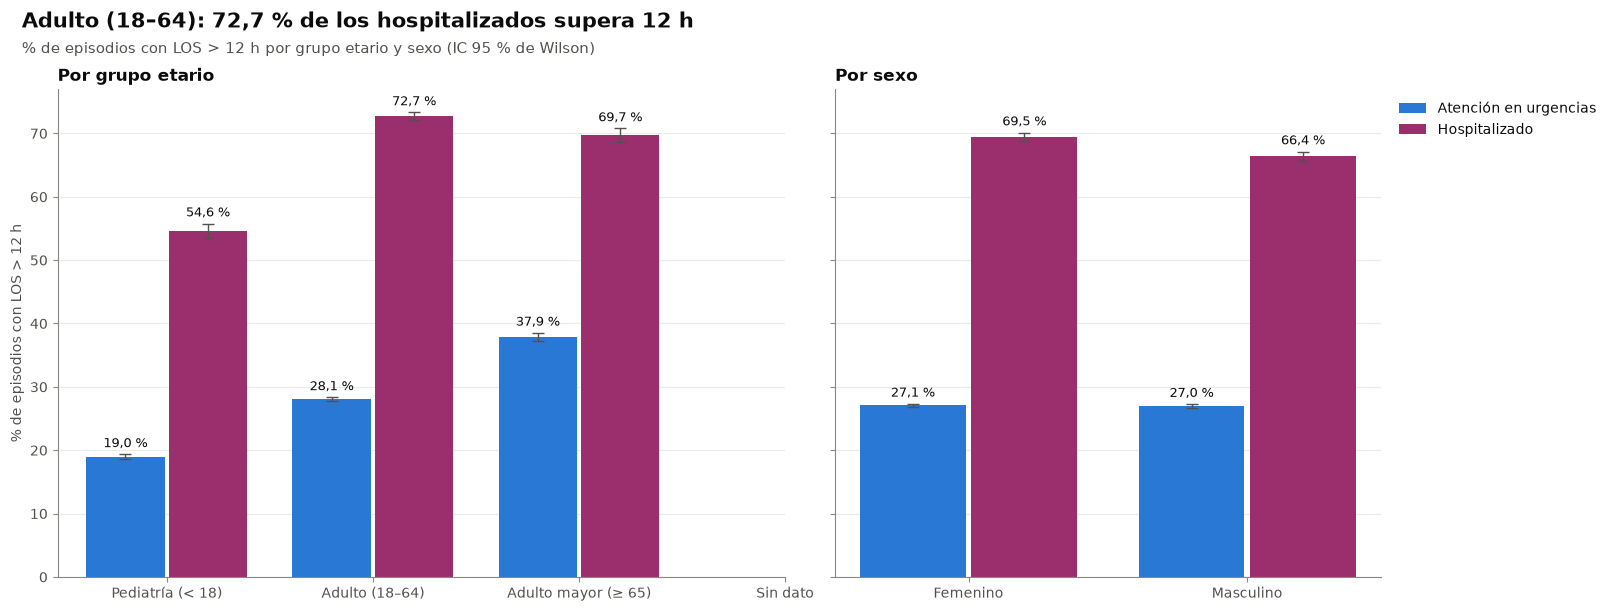

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [4, 3]}, sharey=True)
pct_edad_g3 = {}
for ax, (variable, categorias_posibles, nombres) in zip(ejes, [
    ('grupo_etario', ORDEN_EDAD, estilo.NOMBRE_GRUPO_ETARIO),
    ('sexo', ['femenino', 'masculino'], estilo.NOMBRE_SEXO),
]):
    tabla = tabla_los(tiempos, [variable, 'grupo'], umbrales=[UMBRAL])
    valido = puntos_validos(tabla, f'n_{SUFIJO}')
    categorias = [c for c in categorias_posibles if c in tabla.index.get_level_values(variable)]
    x = np.arange(len(categorias))
    for j, grupo in enumerate(config.GRUPOS_TIEMPOS):
        if grupo not in tabla.index.get_level_values('grupo'):
            continue
        parte = tabla.xs(grupo, level='grupo').reindex(categorias)
        validas = valido.xs(grupo, level='grupo').reindex(categorias, fill_value=False)
        barras_con_ic(ax, x, parte, f'pct_{SUFIJO}', f'ic_inf_{SUFIJO}', f'ic_sup_{SUFIJO}', validas, 0.38,
                      (j - 0.5) * 0.4, color=COLORES_GRUPO[grupo], label=ETIQUETAS_CORTAS_GRUPO[grupo])
        if grupo == G3 and variable == 'grupo_etario':
            pct_edad_g3 = parte[f'pct_{SUFIJO}'].where(validas).dropna().to_dict()
    ax.set_xticks(x, [nombres.get(c, c) for c in categorias])
    ax.set_title('Por grupo etario' if variable == 'grupo_etario' else 'Por sexo')
ejes[0].set_ylabel(f'% de episodios con LOS > {UMBRAL} h')
leyenda_fuera(ejes[1])
if pct_edad_g3:
    mayor = max(pct_edad_g3, key=pct_edad_g3.get)
    titulo = f'{estilo.NOMBRE_GRUPO_ETARIO[mayor]}: {fmt_pct(pct_edad_g3[mayor])} de los hospitalizados supera 12 h'
else:
    titulo = f'Episodios que superan {UMBRAL} h por edad y sexo'
titulo_hallazgo(fig, titulo, f'% de episodios con LOS > {UMBRAL} h por grupo etario y sexo (IC 95 % de Wilson)')
guardar_figura(fig, '03_mas_12h_edad_sexo')
plt.show()

### Lectura
Ver si el adulto mayor tiene más episodios por encima de 12 h que los adultos, y si pediatría se comporta distinto. Las diferencias por sexo suelen ser pequeñas; si los IC se solapan, no hay evidencia de diferencia.

## 7. Hora de llegada × día de la semana

% de episodios del grupo 3 con LOS > 12 h y mediana del LOS del grupo 2. Las celdas con menos de 10 episodios quedan en blanco.

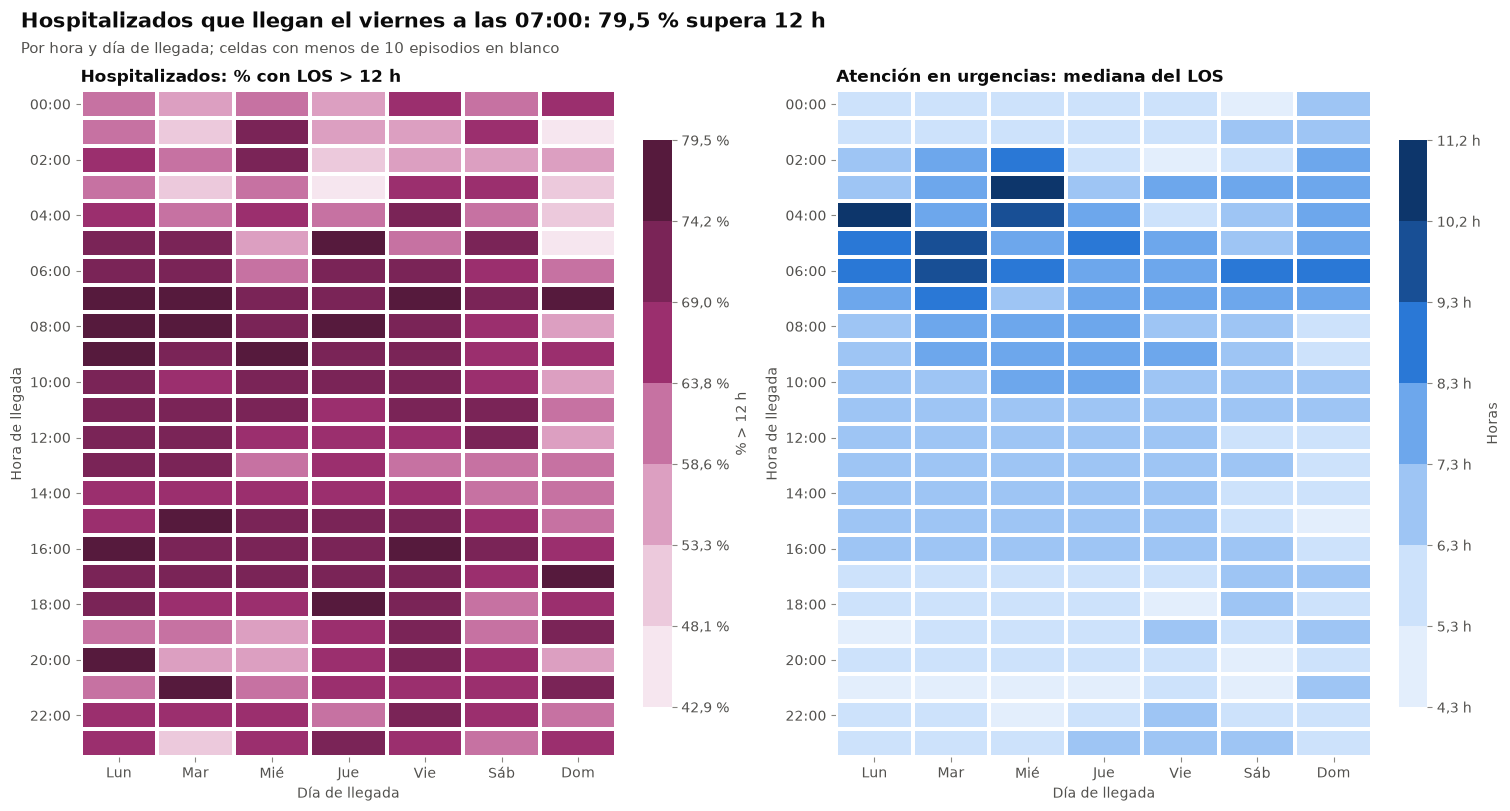

In [11]:
def matriz_hora_dia(datos, columna, estadistico):
    agrupado = datos.groupby(['hora_llegada', 'dia_semana'])[columna]
    n = agrupado.size().unstack('dia_semana')
    valores = agrupado.agg(estadistico).unstack('dia_semana')
    return enmascarar_pequenos(valores, n)


g3 = tiempos[(tiempos['grupo'] == G3) & tiempos['los_h'].notna()].assign(
    supera_umbral=lambda d: 100.0 * (d['los_h'] > UMBRAL)
)
g2 = tiempos[(tiempos['grupo'] == G2) & tiempos['los_h'].notna()]
pct_g3 = matriz_hora_dia(g3, 'supera_umbral', 'mean')
mediana_g2 = matriz_hora_dia(g2, 'los_h', 'median')

fig, ejes = plt.subplots(1, 2, figsize=(15, 8))
heatmap_hora_dia(ejes[0], pct_g3, f'Hospitalizados: % con LOS > {UMBRAL} h', f'% > {UMBRAL} h', familia='ciruela',
                 formato=estilo.tick_pct)
heatmap_hora_dia(ejes[1], mediana_g2, 'Atención en urgencias: mediana del LOS', 'Horas', familia='azul',
                 formato=estilo.tick_horas)
pila = pct_g3.stack()
if not pila.empty:
    hora, dia = pila.idxmax()
    titulo = f'Hospitalizados que llegan el {estilo.DIAS_SEMANA_COMPLETOS[dia]} a las {hora:02d}:00: {fmt_pct(pila.max())} supera 12 h'
else:
    titulo = 'LOS por hora y día de llegada'
titulo_hallazgo(fig, titulo, 'Por hora y día de llegada; celdas con menos de 10 episodios en blanco')
guardar_figura(fig, '03_heatmap_hora_dia')
plt.show()

### Lectura
Buscar franjas (por ejemplo, llegadas de la tarde o del fin de semana) en las que el % > 12 h del grupo 3 sea mayor: apuntan a problemas de salida hacia piso (salida del modelo de Asplin). En el grupo 2, franjas con mediana alta apuntan a congestión del proceso.

## 8. Tendencia mensual

Mediana del LOS y % > 12 h del grupo 3 (con IC de Wilson), y episodios por grupo.

In [12]:
mensual_g3 = tabla_los(tiempos[tiempos['grupo'] == G3], ['mes'], umbrales=[UMBRAL])
mensual_grupos = poblacion.groupby(['mes', 'grupo']).size().unstack('grupo', fill_value=0).reindex(
    columns=list(config.GRUPOS), fill_value=0)
display(tabla_segura(mensual_g3))
display(suprimir_pequenos(mensual_grupos, list(mensual_grupos.columns)))

,n,mediana_h,p25_h,p75_h,p90_h,n_mas_12h,pct_mas_12h,ic_inf_mas_12h,ic_sup_mas_12h
mes,,,,,,,,,
2023-01-01,1.008,"22,91","10,08","36,03","60,60",708,"70,2","67,3","73,0"
2023-02-01,857,"23,89","10,44","39,13","74,91",626,"73,0","70,0","75,9"
2023-03-01,995,"23,47","9,04","40,56","71,99",688,"69,2","66,2","71,9"
2023-04-01,1.003,"24,02","10,42","34,73","59,07",708,"70,6","67,7","73,3"
2023-05-01,997,"25,50","10,44","38,59","79,13",715,"71,7","68,8","74,4"
2023-06-01,967,"25,08","8,88",43,"79,43",674,"69,7","66,7","72,5"
2023-07-01,983,"25,22","10,01","39,07","62,33",697,"70,9","68,0","73,7"
2023-08-01,998,"25,96","9,59","41,14","73,25",701,"70,2","67,3","73,0"
2023-09-01,897,"23,87","9,05","39,42","71,11",619,"69,0","65,9","72,0"


grupo,1_contacto_breve,2_atencion_urgencias,3_hospitalizado
mes,,,
2023-01-01,7.098,5.004,1.008
2023-02-01,6.153,4.527,857
2023-03-01,7.205,5.540,995
2023-04-01,7.030,4.895,1.003
2023-05-01,8.401,5.359,997
2023-06-01,7.173,5.202,967
2023-07-01,7.047,5.268,983
2023-08-01,6.886,5.269,998
2023-09-01,6.174,5.070,897


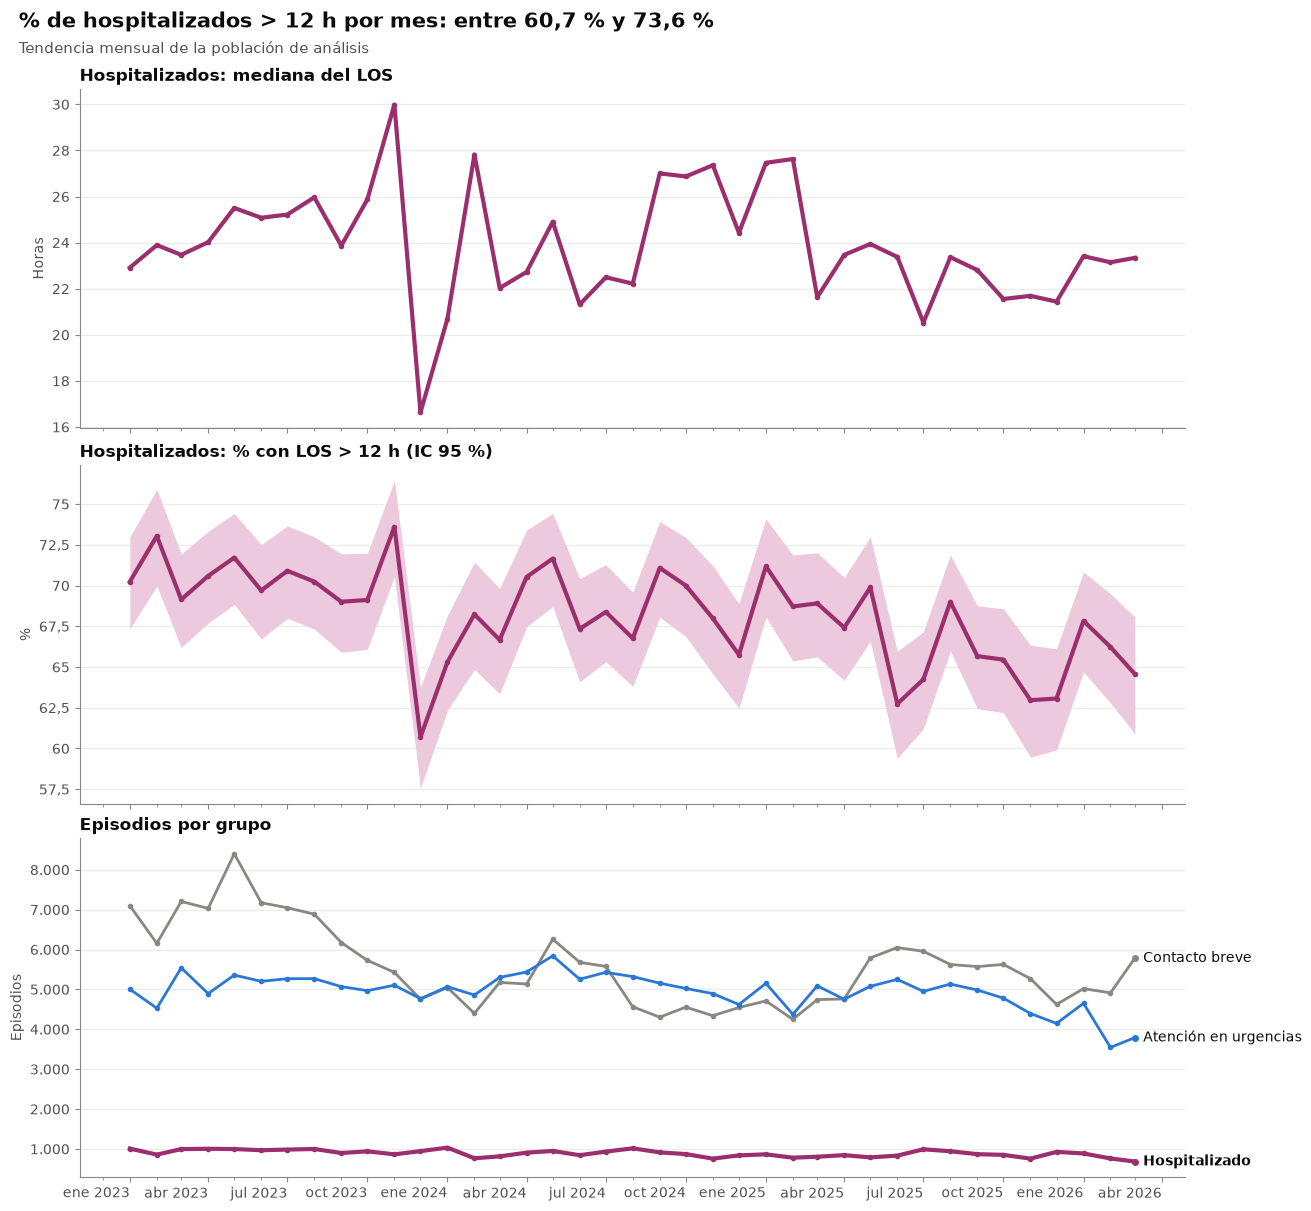

In [13]:
valido = puntos_validos(mensual_g3, f'n_{SUFIJO}')
fig, ejes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)

ejes[0].plot(mensual_g3.index, mensual_g3['mediana_h'].where(mensual_g3['n'] >= config.MIN_CELDA),
             marker='o', markersize=3, color=COLORES_GRUPO[G3], linewidth=ancho_linea(G3))
ejes[0].set_ylabel('Horas')
ejes[0].set_title('Hospitalizados: mediana del LOS')

pct_mes = mensual_g3[f'pct_{SUFIJO}'].where(valido)
ejes[1].plot(mensual_g3.index, pct_mes, marker='o', markersize=3, color=COLORES_GRUPO[G3], linewidth=ancho_linea(G3))
ejes[1].fill_between(mensual_g3.index, mensual_g3[f'ic_inf_{SUFIJO}'].where(valido),
                     mensual_g3[f'ic_sup_{SUFIJO}'].where(valido), color=estilo.RAMPA_CIRUELA[1], linewidth=0)
ejes[1].set_ylabel('%')
ejes[1].set_title(f'Hospitalizados: % con LOS > {UMBRAL} h (IC 95 %)')

for grupo in config.GRUPOS:
    valores = enmascarar_pequenos(mensual_grupos[grupo], mensual_grupos[grupo])
    ejes[2].plot(valores.index, valores, marker='o', markersize=3, color=COLORES_GRUPO[grupo], linewidth=ancho_linea(grupo))
    etiquetas_directas(ejes[2], valores.index, {ETIQUETAS_CORTAS_GRUPO[grupo]: (valores, COLORES_GRUPO[grupo])},
                       negrita=[ETIQUETAS_CORTAS_GRUPO[G3]])
ejes[2].set_ylabel('Episodios')
ejes[2].set_title('Episodios por grupo')
titulo_hallazgo(fig, f'% de hospitalizados > 12 h por mes: entre {fmt_pct(pct_mes.min())} y {fmt_pct(pct_mes.max())}',
                'Tendencia mensual de la población de análisis')
guardar_figura(fig, '03_tendencia_mensual')
plt.show()

### Lectura
Ver si el % > 12 h del grupo 3 sube en los meses de más episodios (relación entre entrada y salida). Revisar que no haya meses con caídas bruscas de volumen dentro del periodo, que indicarían problemas de registro.

## 9. % > 12 h del grupo 3 según hospitalización previa en 30 días

,n,mediana_h,p25_h,p75_h,p90_h,n_mas_4h,pct_mas_4h,ic_inf_mas_4h,ic_sup_mas_4h,n_mas_6h,pct_mas_6h,ic_inf_mas_6h,ic_sup_mas_6h,n_mas_8h,pct_mas_8h,ic_inf_mas_8h,ic_sup_mas_8h,n_mas_12h,pct_mas_12h,ic_inf_mas_12h,ic_sup_mas_12h,n_mas_24h,pct_mas_24h,ic_inf_mas_24h,ic_sup_mas_24h,n_mas_72h,pct_mas_72h,ic_inf_mas_72h,ic_sup_mas_72h
hosp_previa_30d,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
False,33.994,"23,95","8,77","43,05","78,37",29.801,"87,7","87,3","88,0",27.971,"82,3","81,9","82,7",26.135,"76,9","76,4","77,3",23.180,"68,2","67,7","68,7",16.970,"49,9","49,4","50,5",4.050,"11,9","11,6","12,3"
True,663,"26,13","8,54","52,37","96,63",579,"87,3","84,6","89,7",543,"81,9","78,8","84,6",506,"76,3","72,9","79,4",441,"66,5","62,8","70,0",350,"52,8","49,0","56,6",108,"16,3","13,7","19,3"


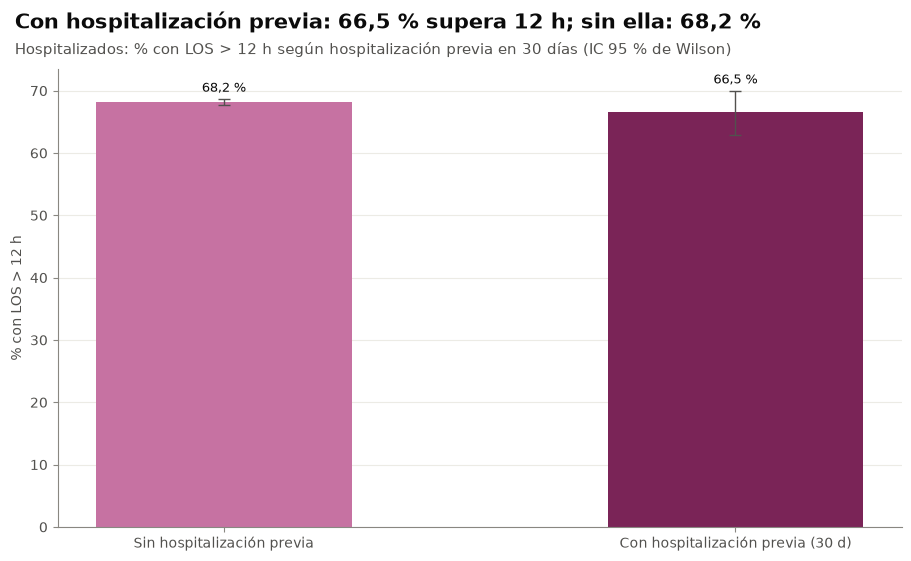

In [14]:
por_hosp_previa = tabla_los(tiempos[tiempos['grupo'] == G3], ['hosp_previa_30d'])
display(tabla_segura(por_hosp_previa))

tabla = por_hosp_previa.reindex([False, True])
valido = puntos_validos(tabla, f'n_{SUFIJO}')
fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(2)
barras_con_ic(ax, x, tabla, f'pct_{SUFIJO}', f'ic_inf_{SUFIJO}', f'ic_sup_{SUFIJO}', valido, 0.5, 0,
              color=[estilo.RAMPA_CIRUELA[3], estilo.RAMPA_CIRUELA[5]])
ax.set_xticks(x, ['Sin hospitalización previa', 'Con hospitalización previa (30 d)'])
ax.set_ylabel(f'% con LOS > {UMBRAL} h')
pct = tabla[f'pct_{SUFIJO}'].where(valido)
titulo_hallazgo(fig, f'Con hospitalización previa: {fmt_pct(pct.iloc[1])} supera 12 h; sin ella: {fmt_pct(pct.iloc[0])}',
                f'Hospitalizados: % con LOS > {UMBRAL} h según hospitalización previa en 30 días (IC 95 % de Wilson)')
guardar_figura(fig, '03_mas_12h_hosp_previa')
plt.show()

### Lectura
Si los reingresos (con hospitalización previa en 30 días) esperan más o menos por cama que el resto, `hosp_previa_30d` es una variable candidata para el modelo predictivo.

## 10. Contactos breves (grupo 1)

Volumen por hora y por mes, y % con `nota_consulta_urg`. No se analizan tiempos.

In [15]:
breves = poblacion[poblacion['grupo'] == G1]
por_hora = pd.DataFrame({
    'n_contactos_breves': breves.groupby('hora_llegada').size(),
    'n_episodios': poblacion.groupby('hora_llegada').size(),
}).fillna(0).astype('int64').rename_axis('hora_llegada')
por_hora['pct_contactos_breves'] = 100 * por_hora['n_contactos_breves'] / por_hora['n_episodios']
display(tabla_segura(por_hora))

por_mes = pd.DataFrame({
    'n_contactos_breves': breves.groupby('mes').size(),
    'n_episodios': poblacion.groupby('mes').size(),
}).fillna(0).astype('int64').rename_axis('mes')
por_mes['pct_contactos_breves'] = 100 * por_mes['n_contactos_breves'] / por_mes['n_episodios']
display(tabla_segura(por_mes))

nota_breves = tabla_proporciones(breves.assign(sin_etapas_txt=breves['sin_etapas'].map({True: 'sin etapas', False: 'con etapas < 5 min'})),
                                 ['sin_etapas_txt'], 'nota_consulta_urg')
display(tabla_segura(nota_breves))
nota_mes = tabla_proporciones(breves, ['mes'], 'nota_consulta_urg')

,n_contactos_breves,n_episodios,pct_contactos_breves
hora_llegada,,,
0,3.230,6.936,"46,6"
1,2.530,5.220,"48,5"
2,1.965,4.312,"45,6"
3,1.883,3.994,"47,1"
4,1.763,3.889,"45,3"
5,3.321,6.620,"50,2"
6,7.261,13.751,"52,8"
7,13.112,25.040,"52,4"
8,16.803,31.668,"53,1"


,n_contactos_breves,n_episodios,pct_contactos_breves
mes,,,
2023-01-01,7.098,13.110,"54,1"
2023-02-01,6.153,11.537,"53,3"
2023-03-01,7.205,13.740,"52,4"
2023-04-01,7.030,12.928,"54,4"
2023-05-01,8.401,14.757,"56,9"
2023-06-01,7.173,13.342,"53,8"
2023-07-01,7.047,13.298,"53,0"
2023-08-01,6.886,13.153,"52,4"
2023-09-01,6.174,12.141,"50,9"


,n,n_eventos,pct_eventos,ic_inf_eventos,ic_sup_eventos
sin_etapas_txt,,,,,
con etapas < 5 min,190.643,70.368,"36,9","36,7","37,1"
sin etapas,26.696,1.606,"6,0","5,7","6,3"


/var/home/luencaro/Programing/College/2026-30/Data Challenge HUN/patient-flow-HUN/src/graficos.py:625: UserWarning: Figura 03_contactos_breves: 26 pares de textos superpuestos, por ejemplo «ene 2023» y «abr 2023»; «abr 2023» y «jul 2023»; «jul 2023» y «oct 2023»; «oct 2023» y «ene 2024»; «ene 2024» y «abr 2024».
  revisar_solapes(fig, nombre)


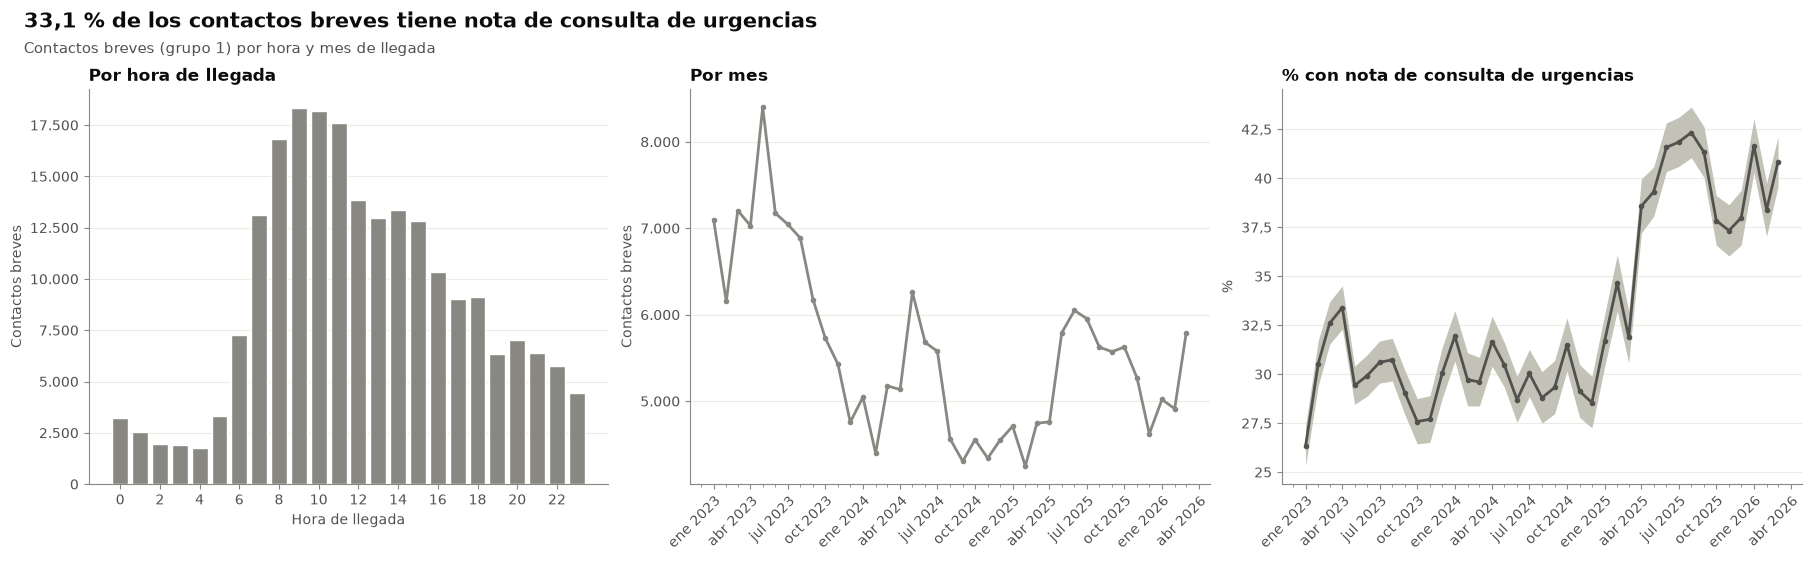

In [16]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5.5))
n_hora = enmascarar_pequenos(por_hora['n_contactos_breves'], por_hora['n_contactos_breves'])
ejes[0].bar(n_hora.index, n_hora, color=estilo.GRIS_CONTEXTO, edgecolor='white', linewidth=1)
ejes[0].set_xticks(range(0, 24, 2))
ejes[0].set_xlabel('Hora de llegada')
ejes[0].set_ylabel('Contactos breves')
ejes[0].set_title('Por hora de llegada')

n_mes = enmascarar_pequenos(por_mes['n_contactos_breves'], por_mes['n_contactos_breves'])
ejes[1].plot(n_mes.index, n_mes, marker='o', markersize=3, color=estilo.GRIS_CONTEXTO)
ejes[1].set_ylabel('Contactos breves')
ejes[1].set_title('Por mes')

valido = puntos_validos(nota_mes)
ejes[2].plot(nota_mes.index, nota_mes['pct_eventos'].where(valido), marker='o', markersize=3, color=OSCURO)
ejes[2].fill_between(nota_mes.index, nota_mes['ic_inf_eventos'].where(valido), nota_mes['ic_sup_eventos'].where(valido),
                     color=CLARO, linewidth=0)
ejes[2].set_ylabel('%')
ejes[2].set_title('% con nota de consulta de urgencias')
titulo_hallazgo(fig, f"{fmt_pct(100 * breves['nota_consulta_urg'].mean())} de los contactos breves tiene nota de consulta de urgencias",
                'Contactos breves (grupo 1) por hora y mes de llegada')
guardar_figura(fig, '03_contactos_breves')
plt.show()

### Lectura
Si los contactos breves se concentran en horas de alta demanda y casi no tienen nota de consulta, son sobre todo triage 4–5 o registros administrativos, como indicó el hospital. Si una parte importante tiene nota de consulta, hay atención médica registrada en menos de 5 min y conviene revisar el corte de D6.

## 11. Reconsultas (D7)
### 11.1 Tasas por grupo

Reconsulta a 72 h y a 7 días, con y sin censura, con IC de Wilson al 95 %. Referencia de DBeaver (reglas anteriores): 5,4 % a 72 h en total.

In [17]:
partes = []
datos = poblacion.assign(total='todos')
for ventana in config.VENTANAS_RECONSULTA:
    for censura, columna in [('con_censura', f'reconsulta_{ventana}'), ('sin_censura', f'reconsulta_{ventana}_sin_censura')]:
        for por in ['grupo', 'total']:
            tabla = tabla_proporciones(datos, [por], columna).rename_axis('grupo')
            partes.append(tabla.assign(ventana=ventana, censura=censura).set_index(['ventana', 'censura'], append=True))

tasas = pd.concat(partes).reorder_levels(['ventana', 'censura', 'grupo']).sort_index()
tabla_segura(tasas)

n  n_eventos  pct_eventos  ic_inf_eventos  ic_sup_eventos
ventana censura     grupo                                                                               
72h     con_censura 1_contacto_breve      217339      12045         5.54            5.45            5.64
                    2_atencion_urgencias  193241      12441         6.44            6.33            6.55
                    3_hospitalizado        34655       1045         3.02            2.84            3.20
                    todos                 445235      25531         5.73            5.67            5.80
        sin_censura 1_contacto_breve      217339      12045         5.54            5.45            5.64
                    2_atencion_urgencias  193241      12441         6.44            6.33            6.55
                    3_hospitalizado        34657       1045         3.02            2.84            3.20
                    todos                 445237      25531         5.73            5.67            5.80
7d      con_censura 1_contacto_breve      217339      17767         8.17            8.06            8.29
                    2_atencion_urgencias  193241      19210         9.94            9.81           10.08
                    3_hospitalizado        34655       2230         6.43            6.18            6.70
                    todos                 445235      39207         8.81            8.72            8.89
        sin_censura 1_contacto_breve      217339      17767         8.17            8.06            8.29
                    2_atencion_urgencias  193241      19210         9.94            9.81           10.08
                    3_hospitalizado        34657       2230         6.43            6.18            6.70
                    todos                 445237      39207         8.81            8.72            8.89

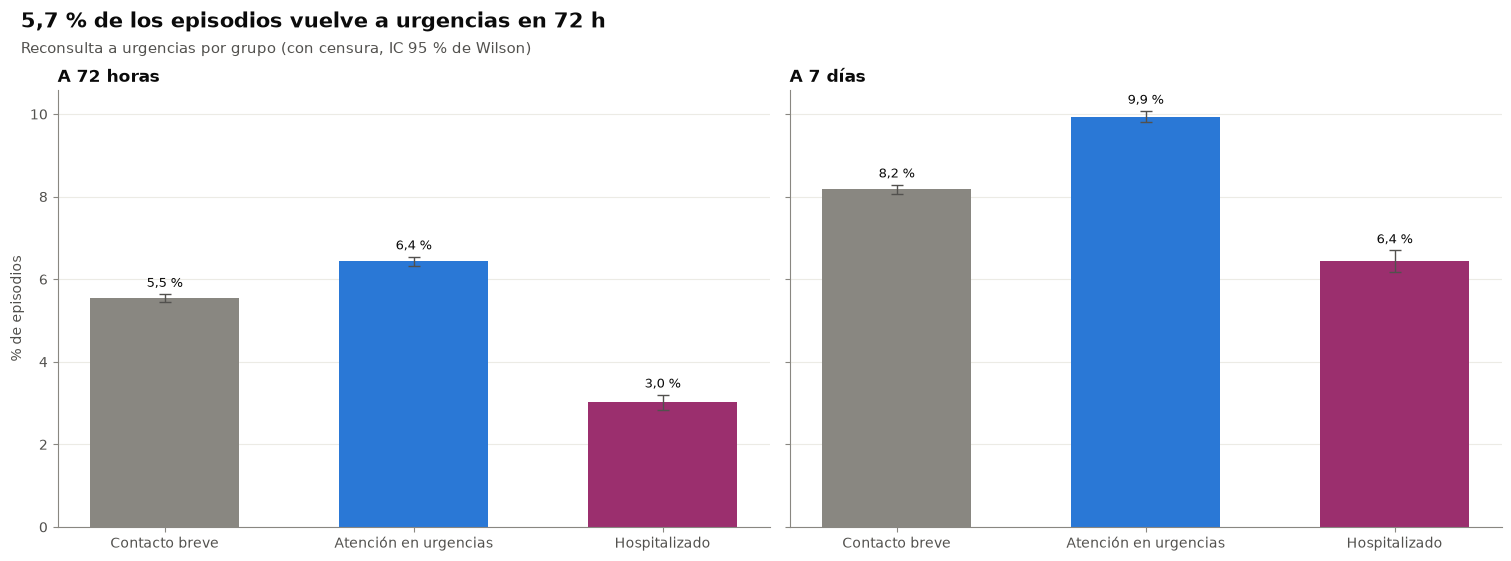

In [18]:
con_censura = tasas.xs('con_censura', level='censura')
grupos = list(config.GRUPOS)
x = np.arange(len(grupos))
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, ventana, titulo in zip(ejes, config.VENTANAS_RECONSULTA, ['A 72 horas', 'A 7 días']):
    tabla = con_censura.xs(ventana, level='ventana').reindex(grupos)
    barras_con_ic(ax, x, tabla, 'pct_eventos', 'ic_inf_eventos', 'ic_sup_eventos', puntos_validos(tabla), 0.6, 0,
                  color=[COLORES_GRUPO[g] for g in grupos])
    ax.set_xticks(x, [ETIQUETAS_CORTAS_GRUPO[g] for g in grupos])
    ax.set_title(titulo)
ejes[0].set_ylabel('% de episodios')
total_72h = valor_seguro(con_censura.xs('72h', level='ventana'), 'todos', 'pct_eventos', 'n_eventos')
titulo_hallazgo(fig, f'{fmt_pct(total_72h)} de los episodios vuelve a urgencias en 72 h',
                'Reconsulta a urgencias por grupo (con censura, IC 95 % de Wilson)')
guardar_figura(fig, '03_reconsulta_por_grupo')
plt.show()

### 11.2 Reconsulta a 72 h por perfil del episodio índice

Con censura. Por grupo etario, hora de llegada y tramo de LOS (solo grupos 2 y 3, que tienen tiempos).

In [19]:
columna_72h = 'reconsulta_72h'
for variable in ['grupo_etario', 'hora_llegada', 'tramo_los']:
    datos = tiempos if variable == 'tramo_los' else poblacion
    display(tabla_segura(tabla_proporciones(datos, ['grupo', variable], columna_72h)))

n n_eventos pct_eventos ic_inf_eventos ic_sup_eventos
grupo                grupo_etario                                                            
1_contacto_breve     adulto        135755      6994        5.15           5.04           5.27
                     adulto_mayor   17329       803        4.63           4.33           4.96
                     pediatria      64242      4247        6.61           6.42           6.81
                     sin_dato          13       <10   suprimido      suprimido      suprimido
2_atencion_urgencias adulto        119107      7791        6.54            6.4           6.68
                     adulto_mayor   24794      1222        4.93           4.67           5.21
                     pediatria      49334      3428        6.95           6.73           7.18
                     sin_dato         <10       <10   suprimido      suprimido      suprimido
3_hospitalizado      adulto         20164       635        3.15           2.92            3.4
                     adulto_mayor    6906       187        2.71           2.35           3.12
                     pediatria       7585       223        2.94           2.58           3.34

n  n_eventos  pct_eventos  ic_inf_eventos  ic_sup_eventos
grupo            hora_llegada                                                              
1_contacto_breve 0             3230        359        11.11           10.08           12.25
                 1             2530        378        14.94           13.60           16.38
                 2             1965        294        14.96           13.45           16.61
                 3             1883        253        13.44           11.97           15.05
                 4             1763        243        13.78           12.25           15.47
...                             ...        ...          ...             ...             ...
3_hospitalizado  19            1218         22         1.81            1.20            2.72
                 20            1289         46         3.57            2.69            4.73
                 21            1202         26         2.16            1.48            3.15
                 22            1085         40         3.69            2.72            4.98
                 23             907         23         2.54            1.70            3.78

[72 rows x 5 columns]

n  n_eventos  pct_eventos  ic_inf_eventos  ic_sup_eventos
grupo                tramo_los                                                                  
2_atencion_urgencias menos de 4 h  73692       5036         6.83            6.65            7.02
                     4 a 12 h      67313       4696         6.98            6.79            7.17
                     12 a 24 h     28561       1867         6.54            6.26            6.83
                     24 h o más    23675        842         3.56            3.33            3.80
3_hospitalizado      menos de 4 h   4276        118         2.76            2.31            3.29
                     4 a 12 h       6760        164         2.43            2.09            2.82
                     12 a 24 h      6301        218         3.46            3.04            3.94
                     24 h o más    17318        545         3.15            2.90            3.42

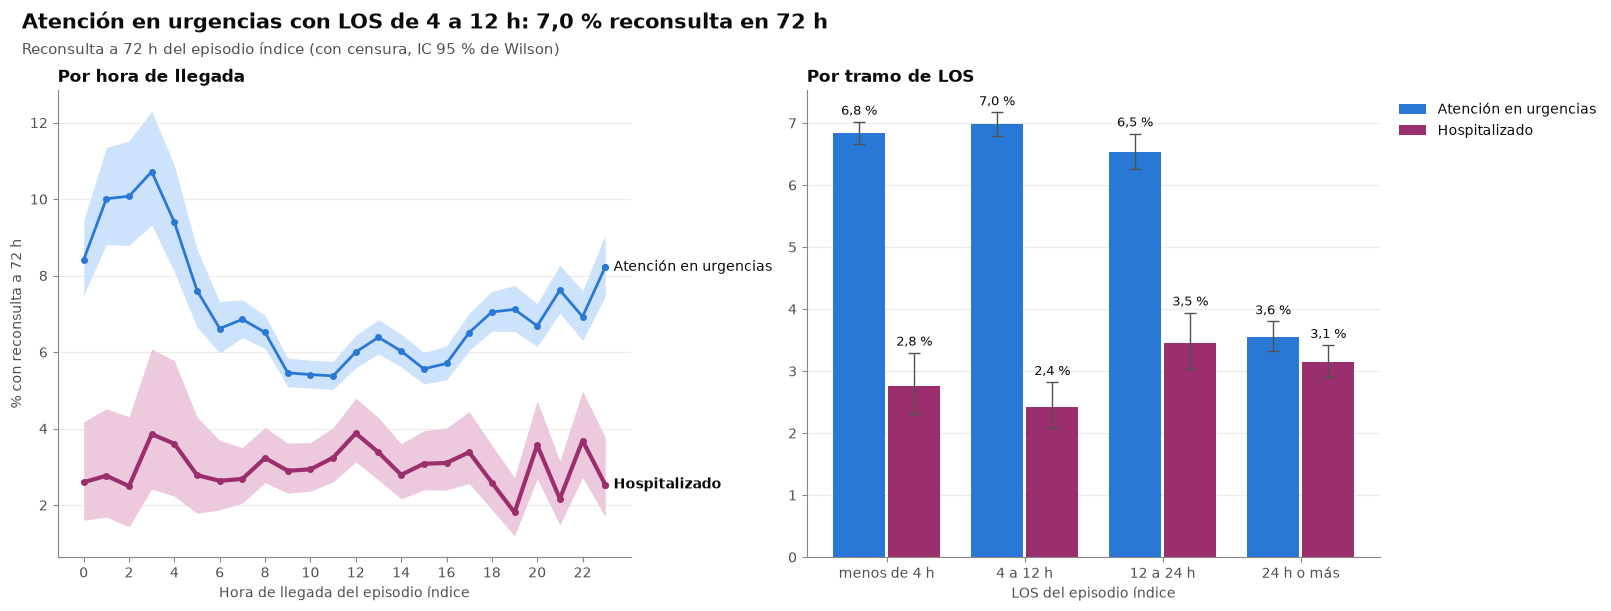

In [20]:
por_hora_r = tabla_proporciones(tiempos, ['grupo', 'hora_llegada'], columna_72h)
por_tramo = tabla_proporciones(tiempos, ['grupo', 'tramo_los'], columna_72h)

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
for grupo in config.GRUPOS_TIEMPOS:
    tabla = por_hora_r.xs(grupo, level='grupo')
    valido = puntos_validos(tabla)
    pct = tabla['pct_eventos'].where(valido)
    color = COLORES_GRUPO[grupo]
    ejes[0].plot(tabla.index, pct, marker='o', markersize=4, color=color, linewidth=ancho_linea(grupo))
    ejes[0].fill_between(tabla.index, tabla['ic_inf_eventos'].where(valido), tabla['ic_sup_eventos'].where(valido),
                         color=estilo.tonos(estilo.FAMILIA_ROL[grupo], 2)[0], linewidth=0)
    etiquetas_directas(ejes[0], tabla.index, {ETIQUETAS_CORTAS_GRUPO[grupo]: (pct, color)},
                       negrita=[ETIQUETAS_CORTAS_GRUPO[G3]])
ejes[0].set_xticks(range(0, 24, 2))
ejes[0].set_xlabel('Hora de llegada del episodio índice')
ejes[0].set_ylabel('% con reconsulta a 72 h')
ejes[0].set_title('Por hora de llegada')

tramos = list(episodios['tramo_los'].cat.categories)
x = np.arange(len(tramos))
pct_tramo_g2 = {}
for j, grupo in enumerate(config.GRUPOS_TIEMPOS):
    tabla = por_tramo.xs(grupo, level='grupo').reindex(tramos)
    barras_con_ic(ejes[1], x, tabla, 'pct_eventos', 'ic_inf_eventos', 'ic_sup_eventos', puntos_validos(tabla),
                  0.38, (j - 0.5) * 0.4, color=COLORES_GRUPO[grupo], label=ETIQUETAS_CORTAS_GRUPO[grupo])
    if grupo == G2:
        pct_tramo_g2 = tabla['pct_eventos'].where(puntos_validos(tabla)).dropna().to_dict()
leyenda_fuera(ejes[1])
ejes[1].set_xticks(x, tramos)
ejes[1].set_xlabel('LOS del episodio índice')
ejes[1].set_title('Por tramo de LOS')
if pct_tramo_g2:
    mayor = max(pct_tramo_g2, key=pct_tramo_g2.get)
    titulo = f'Atención en urgencias con LOS de {mayor}: {fmt_pct(pct_tramo_g2[mayor])} reconsulta en 72 h'
else:
    titulo = 'Reconsulta a 72 h por hora de llegada y tramo de LOS'
titulo_hallazgo(fig, titulo, 'Reconsulta a 72 h del episodio índice (con censura, IC 95 % de Wilson)')
guardar_figura(fig, '03_reconsulta_hora_tramo_los')
plt.show()

### 11.3 Tiempo hasta el siguiente episodio

Distribución, en bloques de 6 horas, del tiempo entre el fin del episodio y la llegada del siguiente durante los primeros 7 días (solo episodios observables a 7 días). Por construcción no hay valores menores al umbral de fusión (60 min).

,n_episodios
horas_hasta_siguiente_tramo,
"(0.0, 24.0]",10.708
"(24.0, 48.0]",8.668
"(48.0, 72.0]",6.155
"(72.0, 96.0]",4.249
"(96.0, 120.0]",3.504
"(120.0, 144.0]",2.962
"(144.0, 168.0]",2.961


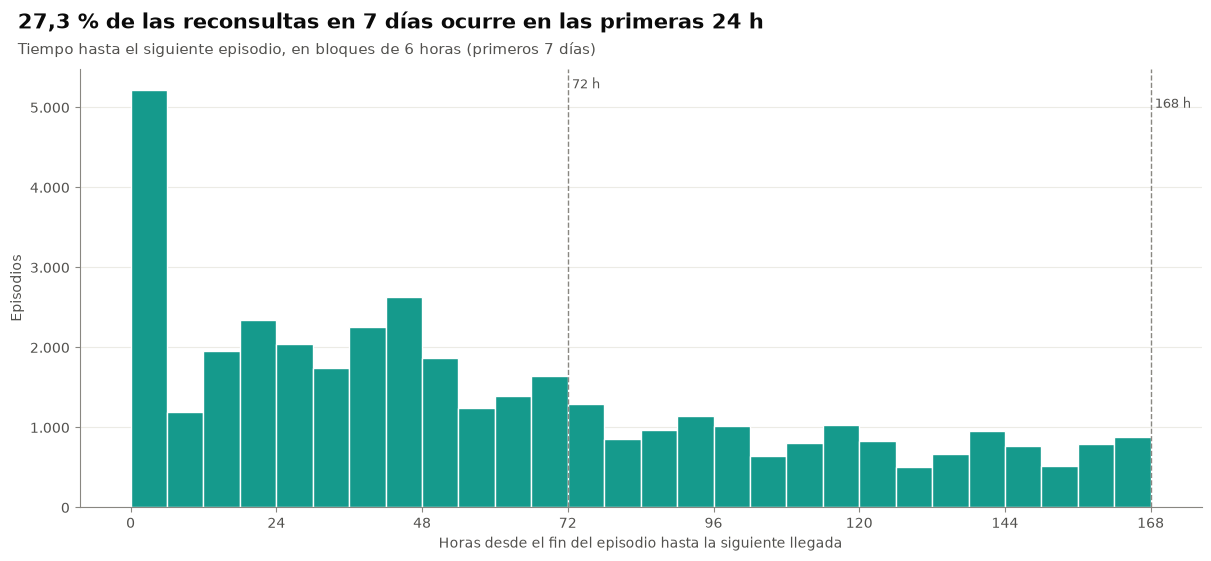

In [21]:
limite_7d_h = config.VENTANAS_RECONSULTA['7d'] / pd.Timedelta(hours=1)
observables = poblacion[poblacion['reconsulta_7d'].notna()]
horas = observables.loc[observables['horas_hasta_siguiente'] <= limite_7d_h, 'horas_hasta_siguiente']

por_dia = (
    pd.cut(horas, bins=np.arange(0, limite_7d_h + 1, 24), right=True)
    .value_counts().sort_index().rename('n_episodios').rename_axis('horas_hasta_siguiente_tramo').to_frame()
)
por_dia.index = por_dia.index.astype(str)
display(suprimir_pequenos(por_dia, ['n_episodios']))

bordes = np.arange(0, limite_7d_h + 1, 6)
conteos, _ = np.histogram(horas, bins=bordes)
conteos_graf = np.where(conteos >= config.MIN_CELDA, conteos, np.nan)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(bordes[:-1], conteos_graf, width=6, align='edge', color=estilo.VERDE, edgecolor='white', linewidth=1)
marcar_umbrales(ax, [72, 168])
ax.set_xticks(range(0, int(limite_7d_h) + 1, 24))
ax.set_xlabel('Horas desde el fin del episodio hasta la siguiente llegada')
ax.set_ylabel('Episodios')
titulo_hallazgo(fig, f'{fmt_pct(100 * (horas <= 24).mean())} de las reconsultas en 7 días ocurre en las primeras 24 h',
                'Tiempo hasta el siguiente episodio, en bloques de 6 horas (primeros 7 días)')
guardar_figura(fig, '03_tiempo_hasta_siguiente')
plt.show()

### 11.4 Episodios por paciente al año

Tabla de frecuencias agregada (1, 2, 3, 4–5, 6–9, 10 o más episodios por paciente y año). 2026 es un año parcial (hasta marzo).

In [22]:
por_paciente_anio = poblacion.groupby([poblacion['person_id'], poblacion['llegada'].dt.year.rename('anio')]).size()
conteo_anual = pd.DataFrame({
    'anio': por_paciente_anio.index.get_level_values('anio'),
    'categoria': pd.cut(
        por_paciente_anio.to_numpy(), bins=[0, 1, 2, 3, 5, 9, np.inf], labels=['1', '2', '3', '4-5', '6-9', '10+']
    ),
    'episodios': por_paciente_anio.to_numpy(),
})
del por_paciente_anio  # se descarta el nivel con identificadores

pacientes = conteo_anual.groupby(['categoria', 'anio'], observed=False).size().unstack('anio', fill_value=0)
episodios_cat = conteo_anual.groupby(['categoria', 'anio'], observed=False)['episodios'].sum().unstack('anio', fill_value=0)
frecuentes = pd.concat(
    [
        pacientes.add_prefix('n_pacientes_'),
        (100 * pacientes / pacientes.sum()).add_prefix('pct_pacientes_'),
        episodios_cat.add_prefix('n_episodios_'),
        (100 * episodios_cat / episodios_cat.sum()).add_prefix('pct_episodios_'),
    ],
    axis=1,
).rename_axis('episodios_por_paciente_anio')
frecuentes.columns.name = None
tabla_segura(frecuentes, decimales=1)

,n_pacientes_2023,n_pacientes_2024,n_pacientes_2025,n_pacientes_2026,pct_pacientes_2023,pct_pacientes_2024,pct_pacientes_2025,pct_pacientes_2026,n_episodios_2023,n_episodios_2024,n_episodios_2025,n_episodios_2026,pct_episodios_2023,pct_episodios_2024,pct_episodios_2025,pct_episodios_2026
episodios_por_paciente_anio,,,,,,,,,,,,,,,,
1,67.054,60.244,61.241,20.784,"68,5","69,6","70,7","84,2",67.054,60.244,61.241,20.784,"44,3","45,5","46,6","69,2"
2,18.932,16.371,15.658,2.975,"19,4","18,9","18,1","12,1",37.864,32.742,31.316,5.950,"25,0","24,7","23,9","19,8"
3,6.676,5.498,5.409,630,"6,8","6,4","6,2","2,6",20.028,16.494,16.227,1.890,"13,2","12,5","12,4","6,3"
4-5,3.885,3.288,3.177,249,"4,0","3,8","3,7","1,0",16.704,14.135,13.666,1.083,"11,0","10,7","10,4","3,6"
6-9,1.088,921,1.017,39,"1,1","1,1","1,2","0,2",7.357,6.286,6.897,264,"4,9","4,7","5,3","0,9"
10+,194,182,150,<10,"0,2","0,2","0,2",suprimido,2.496,2.505,1.952,58,"1,6","1,9","1,5","0,2"


### Lectura
- Comparar la reconsulta a 72 h total con la referencia de DBeaver (5,4 %). Con censura y sin censura deberían ser casi iguales, porque la población termina en marzo de 2026 y los datos siguen después.
- Ver si la reconsulta es mayor en los episodios con LOS corto del grupo 2 (posible alta prematura) o en el adulto mayor.
- En el tiempo hasta el siguiente episodio, un pico en las primeras 24 h sugiere retornos por el mismo motivo.
- En usuarios frecuentes, ver qué porcentaje de los episodios lo generan los pacientes con 4 o más episodios al año.

# Parte C · Cierre
## 12. Resumen de hallazgos en el marco de Asplin

Completar con las cifras que salgan al correr el notebook (los corchetes indican dónde).

**Entrada (demanda).**
- Episodios en la población (2023-01 a 2026-03): [ ].
- Composición: grupo 1 [ ] %, grupo 2 [ ] %, grupo 3 [ ] %.
- Picos de llegada: [hora/día] (sección 3); usuarios frecuentes con 4 o más episodios al año: [ ] % de los pacientes, [ ] % de los episodios (11.4).

**Procesos (atención en urgencias).**
- Grupo 2: mediana del LOS [ ] h; % > 12 h [ ] % (IC [ ]–[ ]).
- Franjas hora × día con mayor mediana del grupo 2: [ ] (sección 7).
- Contactos breves: [ ] % del total; [ ] % con nota de consulta de urgencias (sección 10).

**Salida (hospitalización y egreso).**
- Grupo 3: mediana del LOS hasta piso [ ] h; % > 12 h [ ] % (IC [ ]–[ ]); % > 24 h [ ] %.
- Diferencias por grupo etario: [ ] (sección 6); por hospitalización previa en 30 días: [ ] (sección 9).
- Tendencia: [estable / sube / baja] (sección 8).
- Reconsulta a 72 h: [ ] % en total; grupo 2 [ ] %, grupo 3 [ ] % (sección 11).

**Limitaciones.** Sin triage, sección, destino al egreso ni fallecimientos; población limitada a marzo de 2026 por datos incompletos (D9). Ver el notebook 02.

## 13. Exportación para el dashboard

Tablas largas, agregadas y con supresión de celdas pequeñas. Se guardan en `data/processed/` (ignorado por git).

- `resumen_los.csv`: LOS de los grupos 2 y 3 por dimensión (total, grupo etario, sexo, hora, día de la semana, mes y hospitalización previa).
- `resumen_reconsultas.csv`: reconsulta (72 h y 7 días, con y sin censura) por grupo y dimensión.
- `resumen_grupos_mes.csv`: episodios por mes y grupo, con mediana y % > 12 h de los grupos 2 y 3.

In [23]:
dimensiones = ['total', 'grupo_etario', 'sexo', 'hora_llegada', 'dia_semana', 'mes', 'hosp_previa_30d']
partes = []
for dimension in dimensiones:
    if dimension == 'total':
        categoria = pd.Series('total', index=tiempos.index)
    elif dimension == 'dia_semana':
        categoria = tiempos['dia_semana'].map(dict(enumerate(DIAS_SEMANA)))
    elif dimension == 'mes':
        categoria = tiempos['mes'].dt.strftime('%Y-%m')
    else:
        categoria = tiempos[dimension].astype(str)
    tabla = tabla_los(tiempos.assign(categoria=categoria), ['grupo', 'categoria'])
    partes.append(tabla.assign(dimension=dimension).set_index('dimension', append=True))

resumen_los = pd.concat(partes).reorder_levels(['dimension', 'grupo', 'categoria'])
resumen_los_seguro = tabla_segura(resumen_los, decimales=3)

config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
resumen_los_seguro.reset_index().to_csv(config.DATA_PROCESSED / 'resumen_los.csv', index=False)
print('Filas exportadas a data/processed/resumen_los.csv:', len(resumen_los_seguro))

Filas exportadas a data/processed/resumen_los.csv: 158


In [24]:
dimensiones = ['total', 'grupo_etario', 'sexo', 'hora_llegada', 'tramo_los', 'hosp_previa_30d']
partes = []
for ventana in config.VENTANAS_RECONSULTA:
    for censura, columna in [('con_censura', f'reconsulta_{ventana}'), ('sin_censura', f'reconsulta_{ventana}_sin_censura')]:
        for dimension in dimensiones:
            datos = tiempos if dimension == 'tramo_los' else poblacion
            if dimension == 'total':
                categoria = pd.Series('total', index=datos.index)
            else:
                categoria = datos[dimension].astype(str).where(datos[dimension].notna())
            tabla = tabla_proporciones(datos.assign(categoria=categoria), ['grupo', 'categoria'], columna)
            partes.append(
                tabla.assign(ventana=ventana, censura=censura, dimension=dimension)
                .set_index(['ventana', 'censura', 'dimension'], append=True)
            )

resumen_reconsultas = pd.concat(partes).reorder_levels(['ventana', 'censura', 'dimension', 'grupo', 'categoria'])
resumen_reconsultas_seguro = tabla_segura(resumen_reconsultas, decimales=3)
resumen_reconsultas_seguro.reset_index().to_csv(config.DATA_PROCESSED / 'resumen_reconsultas.csv', index=False)
print('Filas exportadas a data/processed/resumen_reconsultas.csv:', len(resumen_reconsultas_seguro))

Filas exportadas a data/processed/resumen_reconsultas.csv: 432


In [25]:
conteo_mes = poblacion.groupby(['mes', 'grupo']).size().rename('n').to_frame()
conteo_mes['pct_del_mes'] = 100 * conteo_mes['n'] / conteo_mes.groupby(level='mes')['n'].transform('sum')
los_mes = tabla_los(tiempos, ['mes', 'grupo'], umbrales=[UMBRAL])
resumen_grupos_mes = conteo_mes.join(los_mes.drop(columns='n'))
resumen_grupos_mes_seguro = tabla_segura(resumen_grupos_mes, decimales=3).reset_index()
resumen_grupos_mes_seguro['mes'] = resumen_grupos_mes_seguro['mes'].dt.strftime('%Y-%m')
resumen_grupos_mes_seguro.to_csv(config.DATA_PROCESSED / 'resumen_grupos_mes.csv', index=False)
print('Filas exportadas a data/processed/resumen_grupos_mes.csv:', len(resumen_grupos_mes_seguro))

Filas exportadas a data/processed/resumen_grupos_mes.csv: 117
